In [ ]:
%%html
<center><marquee style='width: 60%; color: blue;'><b>✌ ¡Hola a todos! Hoy es una clase importante ✌ </b></marquee><center>

<table>
        <td>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="400"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue"> Conceptos Machine Learning </p> Clasificación </p> CV-Búsqueda en grilla </FONT>         </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Machine Learning </p></tp>
            <tp><p style="font-size:115%;text-align:center">Diplomado 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>




# <FONT SIZE=5 COLOR="purple"> 1. Ejemplo Práctico </FONT>

- En esta sección haremos un ejemplo práctico.

- Iniciaremos indicando las librerías que debemos usar.

## <FONT SIZE=4 COLOR="blue"> 1.1 Librerías de trabajo </FONT>

In [107]:
# Manipulación de data.frames
import pandas       as pd
import numpy        as np

# Librerías para Gráficos
import matplotlib.pyplot  as plt
import seaborn            as sns
import plotly.express     as px

# Librerías para datos de entrenamiento y prueba
from sklearn.model_selection    import train_test_split

# Para preprocesamiento/escalar los datos
from sklearn.preprocessing      import StandardScaler, MinMaxScaler

# Para aplicar k-nearest neighbors

# modelos de clasificación
from sklearn.neighbors          import KNeighborsClassifier
from sklearn.linear_model       import LogisticRegression
from sklearn.tree               import DecisionTreeClassifier

# Métricas de evaluación
from sklearn                    import metrics
from sklearn.metrics            import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics            import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
from imblearn.metrics           import specificity_score

# validación cruzada
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline        import Pipeline

# Optimización de hiperparámetros
from sklearn.model_selection    import GridSearchCV

# Para ignorar los warnings
import warnings
warnings.filterwarnings("ignore")

## <FONT SIZE=4 COLOR="blue"> 1.2 Contexto del problema </FONT>

Una empresa desea desarrollar un modelo de Machine Learning que permita predecir si un empleado renunciará a su puesto de trabajo, utilizando información relacionada con sus características personales y condiciones laborales.

Para ello, se dispone de un conjunto de datos de 5.000 empleados que incluye variables como edad, antigüedad, salario, horas de trabajo, distancia al lugar de trabajo, satisfacción laboral y oportunidades de ascenso, entre otras. El objetivo es construir un modelo de clasificación binaria que permita identificar patrones asociados con la renuncia laboral y estimar la probabilidad de que un empleado abandone la organización.

```python
https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_diplomado.csv
```



El conjunto de datos contiene 10 variables predictoras y una variable objetivo.

| Variable | Descripción | Tipo |
|---|---|---|
| Edad | Edad del empleado en años. | Numérica |
| Antiguedad_anios | Tiempo que lleva trabajando en la empresa, en años. | Numérica |
| Salario_mensual_COP | Salario mensual del empleado en pesos colombianos. | Numérica |
| Horas_semanales | Número de horas trabajadas por semana. | Numérica |
| Distancia_trabajo_km | Distancia entre la vivienda y el lugar de trabajo, en kilómetros. | Numérica |
| Satisfaccion_laboral | Nivel de satisfacción con el trabajo, en una escala de 1 a 5. | Ordinal |
| Balance_vida_trabajo | Percepción del equilibrio entre la vida personal y laboral, en una escala de 1 a 5. | Ordinal |
| Anios_sin_ascenso | Número de años transcurridos desde el último ascenso. | Numérica |
| Trabajo_remoto | Indica si el empleado trabaja de forma remota: 0 = No, 1 = Sí. | Categórica binaria |
| Horas_extra | Indica si el empleado realiza horas extra: 0 = No, 1 = Sí. | Categórica binaria |
| Renuncia | Variable objetivo. Indica si el empleado renuncia: 0 = Permanece, 1 = Renuncia. | Categórica binaria |

Desarrollar y evaluar un modelo de clasificación binaria que permita predecir la renuncia laboral de un empleado a partir de las 10 variables predictoras, utilizando métricas como accuracy, precision, recall, F1-score y matriz de confusión.

Pregunta de investigación: ¿Es posible predecir la renuncia de un empleado a partir de sus características personales y condiciones laborales mediante algoritmos de Machine Learning?



## <FONT SIZE=4 COLOR="blue"> 1.3 Importar los datos </FONT>

Lo primero que haremos es importar los datos que están en el siguiente link o pueden ser descargados de la página de Kaggle.

https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_diplomado.csv

In [108]:
empleados= pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_diplomado.csv")

## <FONT SIZE=4 COLOR="blue"> 1.4 Exploración rápida de los datos </FONT>

Antes de hacer cualquier modelo de machine learning o análisis similar es fundamental entender y explorar las variables del conjunto de datos.

In [109]:
# cabeza de los datos (primeros)
empleados.head()

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
0,50,7,3671886.43,NaN,44.86,3,3,0.0,0,0,1
1,25,6,3223787.18,38.49,2.46,3,2,6.0,0,0,0
2,52,21,5838929.54,46.50,57.24,1,2,3.0,0,0,1
3,34,16,3335062.80,58.91,30.15,5,2,6.0,0,0,1
4,34,0,1633510.55,47.95,21.02,2,4,2.0,1,1,1


In [110]:
# revisar la información de los datos
empleados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Edad                  5000 non-null   int64  
 1   Antiguedad_anios      5000 non-null   object 
 2   Salario_mensual_COP   5000 non-null   float64
 3   Horas_semanales       4999 non-null   float64
 4   Distancia_trabajo_km  5000 non-null   object 
 5   Satisfaccion_laboral  5000 non-null   int64  
 6   Balance_vida_trabajo  5000 non-null   int64  
 7   Anios_sin_ascenso     4999 non-null   float64
 8   Trabajo_remoto        5000 non-null   int64  
 9   Horas_extra           5000 non-null   int64  
 10  Renuncia              5000 non-null   int64  
dtypes: float64(3), int64(6), object(2)
memory usage: 429.8+ KB


observamos dos cosas importante:

1. Hay datos faltantes en las variables `Horas_semanales` y `Anios_sin_ascenso`

2. Hay inconsistencias en `Distancia_trabajo_km` y `Antiguedad_anios`

## <FONT SIZE=4 COLOR="blue"> 1.5 Preprocesar los datos </FONT>

Como hay inconsistencias, primero debemos arreglarlas

Para la primera eliminamos los `Na's`

In [111]:
# contar los datos faltantes
empleados.isna().sum()

,0
Edad,0
Antiguedad_anios,0
Salario_mensual_COP,0
Horas_semanales,1
Distancia_trabajo_km,0
Satisfaccion_laboral,0
Balance_vida_trabajo,0
Anios_sin_ascenso,1
Trabajo_remoto,0
Horas_extra,0


Los vamos a eliminar

In [112]:
# eliminar los datos faltantes
empleados = empleados.dropna()

In [113]:
empleados.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4998 entries, 1 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Edad                  4998 non-null   int64  
 1   Antiguedad_anios      4998 non-null   object 
 2   Salario_mensual_COP   4998 non-null   float64
 3   Horas_semanales       4998 non-null   float64
 4   Distancia_trabajo_km  4998 non-null   object 
 5   Satisfaccion_laboral  4998 non-null   int64  
 6   Balance_vida_trabajo  4998 non-null   int64  
 7   Anios_sin_ascenso     4998 non-null   float64
 8   Trabajo_remoto        4998 non-null   int64  
 9   Horas_extra           4998 non-null   int64  
 10  Renuncia              4998 non-null   int64  
dtypes: float64(3), int64(6), object(2)
memory usage: 468.6+ KB


Ahora, debemos revisar por qué tenemos datos tipos `object`

In [114]:
# revisar la variable Antiguedad_anios
empleados["Antiguedad_anios"].unique()

array(['6', '21', '16', '0', '24', '5', '18', '8', '7', '22', '26', '15',
       '14', '10', '2', '27', '30', '9', '13', '3', '11', '25', '23',
       '12', '29', '20', '19', '17', '1', '4', '28', ' '], dtype=object)

Aparecen entre comillas, eso quiere decir que en la variable hay texto o caracteres especiales.

In [115]:
# Intentar convertir a numérico
numerica = pd.to_numeric(empleados["Antiguedad_anios"], errors='coerce')

# Identificar valores que no pudieron convertirse
problemas = empleados[numerica.isna() & empleados["Antiguedad_anios"].notna()]

display(problemas)

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
170,44,,1994223.53,40.35,4.10,4,5,3.0,0,1,1


In [116]:
# Intentar convertir a numérico Distancia_trabajo_km
numerica = pd.to_numeric(empleados["Distancia_trabajo_km"], errors='coerce')

# Identificar valores que no pudieron convertirse
problemas_2 = empleados[numerica.isna() & empleados["Distancia_trabajo_km"].notna()]

display(problemas_2)

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
21,27,9,3862356.36,40.31,,4,1,3.0,0,1,1


In [117]:
# eliminar los registros 21 y 170
empleados = empleados.drop([21,170])

In [118]:
# cambiar las variables a numéricas
empleados["Antiguedad_anios"] = pd.to_numeric(empleados["Antiguedad_anios"])
empleados["Distancia_trabajo_km"] = pd.to_numeric(empleados["Distancia_trabajo_km"])

In [119]:
empleados.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4996 entries, 1 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Edad                  4996 non-null   int64  
 1   Antiguedad_anios      4996 non-null   int64  
 2   Salario_mensual_COP   4996 non-null   float64
 3   Horas_semanales       4996 non-null   float64
 4   Distancia_trabajo_km  4996 non-null   float64
 5   Satisfaccion_laboral  4996 non-null   int64  
 6   Balance_vida_trabajo  4996 non-null   int64  
 7   Anios_sin_ascenso     4996 non-null   float64
 8   Trabajo_remoto        4996 non-null   int64  
 9   Horas_extra           4996 non-null   int64  
 10  Renuncia              4996 non-null   int64  
dtypes: float64(4), int64(7)
memory usage: 468.4 KB


Ahora, las estadísticas descriptivas.

In [120]:
# estadísticos descriptivos
empleados.describe()

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
count,4996.000000,4996.000000,4.996000e+03,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000
mean,42.179944,11.946757,3.693091e+06,43.168713,32.790504,3.014412,2.978183,4.930344,0.494996,0.502802,0.501801
std,13.658169,8.166214,1.552922e+06,6.776675,18.782772,1.412299,1.413266,3.172888,0.500025,0.500042,0.500047
min,19.000000,0.000000,1.400000e+06,30.000000,0.520000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,5.000000,2.449955e+06,38.470000,16.177500,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000
50%,42.000000,11.000000,3.572854e+06,43.110000,33.015000,3.000000,3.000000,5.000000,0.000000,1.000000,1.000000
75%,54.000000,18.000000,4.765366e+06,47.810000,49.142500,4.000000,4.000000,8.000000,1.000000,1.000000,1.000000
max,65.000000,30.000000,9.305460e+06,65.000000,64.990000,5.000000,5.000000,10.000000,1.000000,1.000000,1.000000


Ahora revisamos la variable objetivo

In [121]:
# contar las categorias de la variable resultado
empleados["Renuncia"].value_counts()

,count
Renuncia,
1,2507
0,2489


Vamos a exportar los datos

In [122]:
# exportar los datos
empleados.to_csv("empoleados_limpio.csv", index=False)

Los datos están balanceados y eso es bueno para el entrenamiento de los modelos

In [123]:
# sirve para evaluar modelos de clasificación binaria.
def evaluacion_modelo(modelo, X_train, y_train, X_test, y_test, nombre_modelo = "modelo",graficar = True):
  # definir las predicciones en conjuntos de train y test
  y_pred_train = modelo.predict(X_train)
  y_pred_test  = modelo.predict(X_test)
  # matrices de confusión
  if graficar :
    # Calcular matrices de confusión
    cm_train = confusion_matrix(y_train, y_pred_train)
    cm_test = confusion_matrix(y_test, y_pred_test)
    # ejes para gráficas
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    # matriz de confusión en train
    sns.heatmap(pd.DataFrame(cm_train),                # data.frame
                  annot=True,                          # colocar números de las cajitas
                  annot_kws = {'size':20},             # tamaño de la letra
                  cmap="YlOrRd",                       # color de la letra 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu'
                  fmt='g',                             # para que salgan los número no : notación científica
                  ax=axes[0])
    axes[0].set_title(f'Matriz de Confusión - Train-{nombre_modelo}', fontsize=14)
    axes[0].set_xlabel('Predicciones')
    axes[0].set_ylabel('Valores Reales')
    # matriz de confusión en test
    sns.heatmap(pd.DataFrame(cm_test),
              annot=True,
              fmt='g',
              cmap='YlOrRd',
              annot_kws={'size':20},
              ax=axes[1])
    axes[1].set_title(f'Matriz de Confusión - Test-{nombre_modelo}', fontsize=14)
    axes[1].set_xlabel('Predicciones')
    axes[1].set_ylabel('Valores Reales')
    plt.tight_layout()
    plt.show()
  # metricas en train
  metrics=["accuracy", "recall" , "specificity", "precision", "f1"]
  # valores
  values_train = [accuracy_score(y_train,y_pred_train),
          recall_score(y_train,y_pred_train),
          specificity_score(y_train,y_pred_train),
          precision_score(y_train,y_pred_train),
          f1_score(y_train,y_pred_train)]
  values_test = [accuracy_score(y_test,y_pred_test),
          recall_score(y_test,y_pred_test),
          specificity_score(y_test,y_pred_test),
          precision_score(y_test,y_pred_test),
          f1_score(y_test,y_pred_test)]

  df = pd.DataFrame({f"{nombre_modelo}_train" : values_train,
                      f"{nombre_modelo}_test" : values_test}, index = metrics)
  return df


## <FONT SIZE=4 COLOR="blue"> 1.6 Modelos de K-vecinos más cercanos preprocesar los datos </FONT>

Vamos a plantear el modelo **knn** vecinos más cercanos

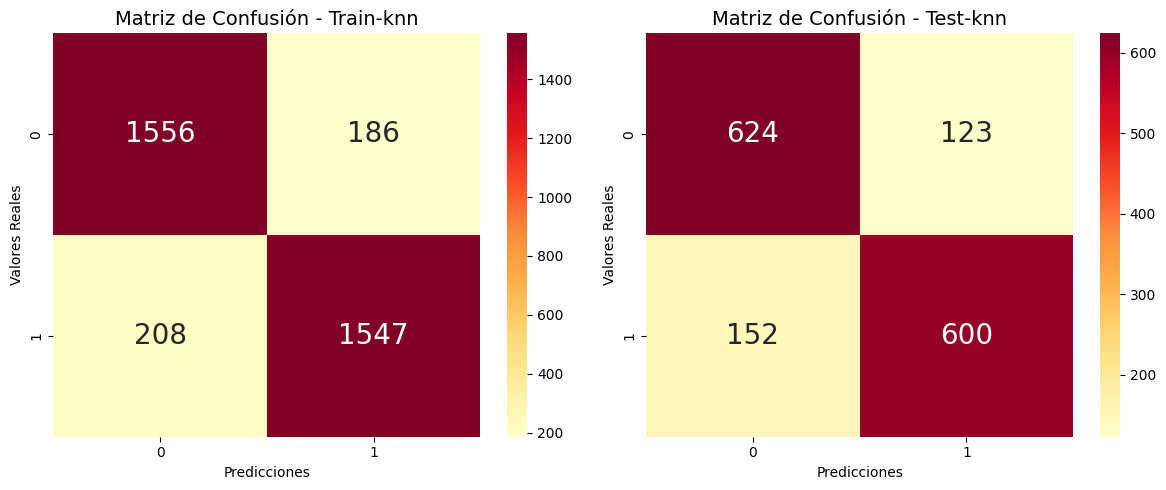

,knn_train,knn_test
accuracy,0.887332,0.816544
recall,0.881481,0.797872
specificity,0.893226,0.835341
precision,0.892672,0.829876
f1,0.887041,0.813559


In [124]:
# 1. Seleccionar variable objetivo y predictoras
# la variable objetivo
y = empleados["Renuncia"]
# las variables predictoras
X = empleados.drop("Renuncia", axis=1)

# 2. Dividir en dos conjuntos: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    stratify = y,             # garantiza que los resultados se distribuyan igual
                                                    random_state = 123,        # semilla para que al ejecutar siempre de igual
                                                    test_size = 0.3)          # tamaño del conjunto de prueba (también se puede train)


# 3. escalar las variables.
# definimos la función para escalar
escalar = StandardScaler()
# lo aplicamos a los conjuntos (s: scaler)
X_train_s = escalar.fit_transform(X_train)
X_test_s = escalar.transform(X_test)

# 4. Generar el modelo
# definir el modelo
# defecto toma 5 vecinos
modelo_knn = KNeighborsClassifier()
# entrenar el modelo
modelo_knn.fit(X_train_s,y_train)

# 5. Evaluar el modelo
evaluacion_modelo(modelo_knn, X_train_s, y_train, X_test_s, y_test, nombre_modelo = "knn",graficar = True)


Otra forma de revisar las métricas es con el *classification_report*

In [125]:
y_pred = modelo_knn.predict(X_test_s)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.84      0.82       747
           1       0.83      0.80      0.81       752

    accuracy                           0.82      1499
   macro avg       0.82      0.82      0.82      1499
weighted avg       0.82      0.82      0.82      1499



# <FONT SIZE=5 COLOR="purple"> 2. Validación Cruzada </FONT>

La **validación cruzada**, o *cross validation*, es una técnica utilizada para evaluar los resultados obtenidos de un modelo de *machine learning* y garantizar que son independientes de los conjuntos de entrenamiento ($X_{train}$) y prueba ($X_{test}$).

- Cuando usamos la función de *sklearn*:

$$train\_test\_split(X, y, random\_state = 123 )$$

se extraen dos muestras aleatorias como conjuntos de entrenamiento y prueba. Luego se hace el proceso de entrenamiento y validación del modelo, teniendo como referencias las muestras seleccionadas. Sin embargo, una pregunta natural es:

**¿Qué sucede si tomo otras muestras como conjunto de entrenamiento y de prueba, obtendré los mismos resultados?**

Para responder lo anterior, debemos seleccionar varias muestras que correspondan a conjunto de entrenamiento y prueba diferentes y hacer el análisis del modelo. Precisamente, esto es lo que hace el proceso de validación cruzada.

Se divide el conjunto de datos en $n$ partes, de las cuales se toma una como conjunto de *prueba* y las otras $n-1$ como conjunto de entrenamiento. Y vamos rotando el conjunto de prueba, tal y como se muestra en la siguiente figura.

<br>

<center><img src="https://github.com/Fabian830348/cursos/blob/master/val_cruzada/validation1.png?raw=true?" alt="centered image" width="600" height="350"></center>

<br>

In [ ]:
# definimos el pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10,
                     shuffle=True,
                     random_state=42)

# Evaluar el pipeline con validación cruzada
resultados = cross_val_score(pipeline,
                             X_train,
                             y_train,
                             cv=cv,
                             scoring="accuracy")

print("Accuracy por partición:", resultados)
print(f"Accuracy promedio: {resultados.mean():.4f}")
print(f"Desviación estándar: {resultados.std():.4f}")

Accuracy por partición: [0.79142857 0.82857143 0.82       0.80285714 0.84285714 0.85428571
 0.82857143 0.85673352 0.83094556 0.83381089]
Accuracy promedio: 0.8290
Desviación estándar: 0.0195


Obtenemos en promedio 0.83 de *Accuracy*

# <FONT SIZE=5 COLOR="purple"> 3. Parámetro vs Hiperparámetro </FONT>

Iniciaremos definiendo los siguientes conceptos:

**Parámetros**:

- Son variables propias del modelo y que se obtienen de forma automática usando el conjunto de entrenamiento. Es decir, se estiman a partir de los datos.  

- Por ejemplo, en regresión lineal buscamos una ecuación de la forma $y= \beta_1 x +\beta_0$ y precisamente este tipo de modelo nos ayuda a encontrar estos valores de $\beta_1$ y $\beta_0$.

***Hiperparámetros:***

- Son parámetros de aprendizaje automático que se eligen antes de iniciar el proceso de aprendizaje automático.

- Son variables externas al modelo que no se obtienen automáticamente a partir de los datos.

- Son ajustables y pueden afectar directamente a la forma en la que se entrena un modelo de aprendizaje automático.

Algunos de estos hiperparámetros son:

- *Número de vecinos en knn*

- *Número de épocas en redes neuronales*

- *Número de ramas en un árbol de decisión*

- *Número de clústeres en un algoritmo de agrupamiento*

- *Tipo de kernel en SVM*

Los hiperparámetros son flexibles, ya que se refieren a cualquier elemento en el machine learning y el deep learning que decida sus valores o elija su configuración antes de que comience el entrenamiento y cuyos valores permanecen iguales cuando se finaliza el entrenamiento.

Los parámetros, por su lado, son características inherentes al modelo. Esto quiere decir que se aprenden o se estiman a partir de los datos brindados durante el entrenamiento, ya que el algoritmo que se use intentará aprender a partir de las características de entrada y la variable objetivo.

**Hiperparámetros de KNN**

Particularmente en el algoritmo de ***knn***, k-vecinos más cercanos tenemos los siguientes hiperpámetros.

- El ***número de vecinos*** $k$.

- Las ***métricas***. Las más clásicas se pueden seleccionar entre:

   - Euclideana
   - Manhattan
   - Minkowski

- Los ***pesos*** en las métricas.

   - Uniformes
   - Respecto a la distancia.  

Podemos ver la documentación para ampliar la información

[ALGORITMO KNN-sklearn 🌎](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)


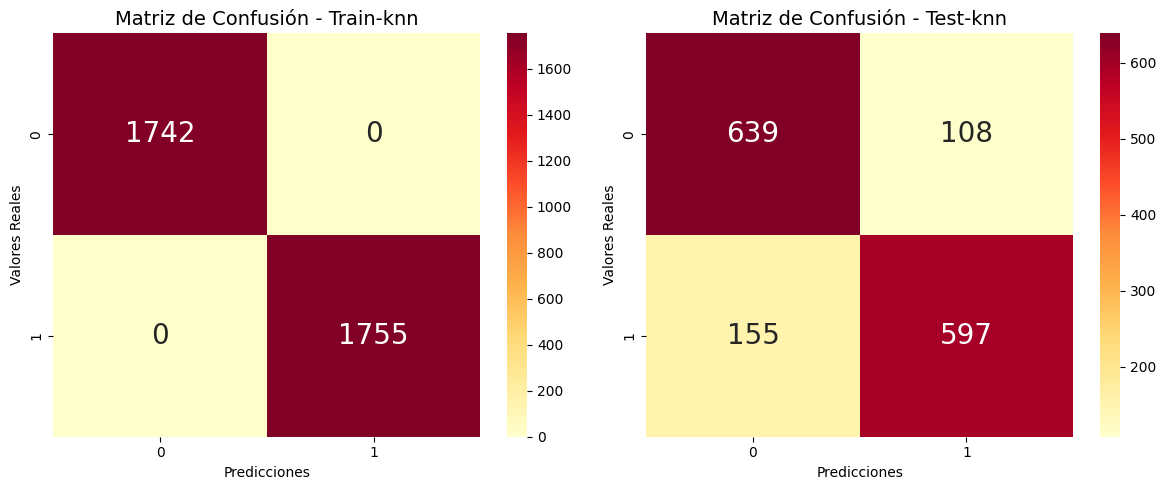

,knn_train,knn_test
accuracy,1.0,0.824550
recall,1.0,0.793883
specificity,1.0,0.855422
precision,1.0,0.846809
f1,1.0,0.819492


In [ ]:
from sklearn import metrics
#metrics.confusion_matrix(y_test, y_pred)

# 1. Seleccionar variable objetivo y predictoras
# la variable objetivo
y = empleados["Renuncia"]
# las variables predictoras
X = empleados.drop("Renuncia", axis=1)

# 2. Dividir en dos conjuntos: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    stratify = y,             # garantiza que los resultados se distribuyan igual
                                                    random_state = 123,        # semilla para que al ejecutar siempre de igual
                                                    test_size = 0.3)          # tamaño del conjunto de prueba (también se puede train)

# 3. Escalar las variables
escalar = StandardScaler()
X_train_s = escalar.fit_transform(X_train)
X_test_s = escalar.transform(X_test)

# 4. Mefinir el modelo (hiperparámetros)
modelo_knn_2 = KNeighborsClassifier(n_neighbors= 7,        # 4,5,6,, etc
                                    metric = "euclidean",  # minkowski, manhattan, euclidean
                                    weights = "distance")   # uniform , distance

# 5. Entrenar el modelo
modelo_knn_2.fit(X_train_s,y_train)

# 6. Evaluar el modelo
evaluacion_modelo(modelo_knn_2, X_train_s, y_train, X_test_s, y_test, nombre_modelo = "knn",graficar = True)

# <FONT SIZE=5 COLOR="purple"> 4. Búsqueda en Grilla </FONT>

- La ***búsqueda en grilla*** (grid search) es un método que busca las mejores combinaciones de hiperparámetros que hacen que un modelo tenga el error más bajo, es decir, estimaciones más precisas.

- En cada combinación de hiperparámetros, la búsqueda en grilla aplica el proceso de *cross-validation* con el fin de dar una mejor evaluación del modelo en cada punto.

- Cuando hablamos de búsqueda en grilla tenemos algunas alternativas: Grid Search y Random Grid Search. La primera se denomina propiamente *Grid Search* y en este método, se toman todas las combinaciones posibles de los hiperparámetros que se van a revisar. Como se ilustra en la siguiente gráfica.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/val_cruzada/grid1.png?raw=true?" alt="centered image" width="600" height="350"></center>
<br>

- Por otro lado, tenemos el ***Random Search***, que es una versión del primero donde no se toman todas las combinaciones de hiperparámetros sino que se selecciona una determinada cantidad aleatoria de combinaciones. Este método es útil cuando se tienen muchos hiperparámetros y el procesamiento puede demorarse.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/val_cruzada/grid2.png?raw=true?" alt="centered image" width="600" height="400"></center>

Para hacer la búsqueda en grilla, vamos a considerar los siguientes parámetros

1. El número de vecinos $k$ : [1,20]
2. Las métricas : *euclideana* y *manhattan*
3. Los pesos: "uniformes" o basados en "distancia"

De acuerdo con lo anterior tenemos

$$(20 \, vecinos) \times ( 2 \, metricas) \times ( 2 \, pesos) = 80$$

combinaciones de hiperparámetros.

In [ ]:
from sklearn.pipeline import Pipeline

# Crear pipeline con escalador y modelo
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# definimos los hiperparámetros que vamos a combinar. Diccionario
grid_params = {"knn__n_neighbors" : list(range(1, 21)),         # se recorre la lista en k
               "knn__weights" : ["uniform","distance"],         # se establecen los pesos
               "knn__metric" : ["euclidean","manhattan"]}       # se establecen las métricas

# hacemos la búsqueda en grilla con 5-folds
Grid_Search = GridSearchCV(pipe,                                     # el modelo aplicado
                           grid_params,                             # los parámetros que van a variar
                           cv = 10,                                 # el número de folds
                           verbose = 1)                             # para que imprima resultados. Posibilidades: 1,2 o 3
# Entrenar el modelo obtenido arriba
g_res = Grid_Search.fit(X_train,y_train)

Fitting 10 folds for each of 80 candidates, totalling 800 fits


Revisemos los siguientes elementos

In [ ]:
# el mejor accuracy
print("Mejor score: ",g_res.best_score_)
# los mejores hiperparámetros
print("Mejores hiperparámetros", g_res.best_params_)
# el mejor modelo
modelo_knn_best = g_res.best_estimator_

Mejor score:  0.8518804748260335
Mejores hiperparámetros {'knn__metric': 'manhattan', 'knn__n_neighbors': 20, 'knn__weights': 'distance'}


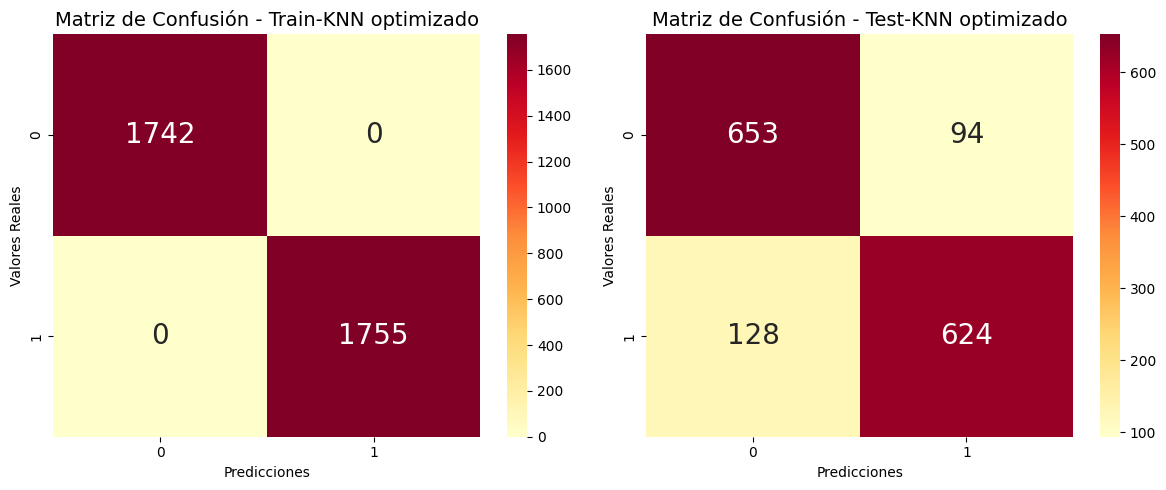

,KNN optimizado_train,KNN optimizado_test
accuracy,1.0,0.851901
recall,1.0,0.829787
specificity,1.0,0.874163
precision,1.0,0.869081
f1,1.0,0.848980


In [ ]:
# evaluar el modelo optimizado
evaluacion_modelo(modelo_knn_best,X_train,y_train,X_test,y_test,nombre_modelo="KNN optimizado")

# <FONT SIZE=5 COLOR="purple"> 5. Comparación de los modelos de knn </FONT>

Después de hacer el proceso tenemos los siguientes resultados.

| Modelo | Accuracy train | Accuracy test |
|---|---:|---:|
| KNN por defecto | 88.73 % | 81.65 % |
| KNN manual, k=7 | 100 % | 82.45 % |
| **KNN optimizado, k=20** | **100 %** | **85.19 %** |

se observa que la optimización de hiperparámetros mejoró 3 puntos porcentuales el modelo.

Ahora, vamos a hacer predicciones

# <FONT SIZE=4 COLOR="Purple"> 6. Predicciones con el modelos de K-vecinos más cercanos </FONT>

In [ ]:
empleados_predicciones = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_nuevos_50_prediccion.csv")
empleados_predicciones.head()

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra
0,39,4,3558900.55,43.97,44.00,3,1,2,0,0
1,45,4,3846442.44,47.98,13.82,4,5,0,1,1
2,34,13,4569842.15,63.78,12.27,4,5,8,0,0
3,21,2,1400000.00,47.80,29.63,1,5,2,1,1
4,63,18,4274175.30,49.11,28.82,5,2,8,1,1


In [ ]:
# escalar los datos
#empleados_predicciones_s = escalar.transform(empleados_predicciones)

In [ ]:
predicciones = modelo_knn_best.predict(empleados_predicciones)

In [ ]:
probabilidades = modelo_knn_best.predict_proba(empleados_predicciones)[:,1]

In [ ]:
# predicciones y las probabilidades
empleados_predicciones["predicciones"] = predicciones
empleados_predicciones["probab"] = probabilidades


In [ ]:
empleados_predicciones.head(10)

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,predicciones,probab
0,39,4,3558900.55,43.97,44.00,3,1,2,0,0,1,0.866763
1,45,4,3846442.44,47.98,13.82,4,5,0,1,1,0,0.089506
2,34,13,4569842.15,63.78,12.27,4,5,8,0,0,0,0.237163
3,21,2,1400000.00,47.80,29.63,1,5,2,1,1,0,0.379992
4,63,18,4274175.30,49.11,28.82,5,2,8,1,1,1,0.760408
5,27,9,4783280.32,38.69,27.35,5,5,8,0,1,0,0.031516
6,64,28,5231012.81,47.49,38.69,2,3,4,1,0,0,0.299524
7,49,25,5134345.84,50.81,42.07,1,2,10,1,1,1,0.941669
8,56,12,2325647.27,53.77,51.79,1,3,9,1,1,1,1.000000
9,63,12,5030468.22,37.63,64.00,2,3,4,0,0,1,0.785235
